# NEXUS LLM — Module 5: Generation Lab

Explore how a causal language model turns a prompt into generated text.

This notebook covers greedy decoding, sampling, temperature, Top-K, Top-P, repetition controls, stopping criteria, KV cache, strategy comparison, and a reusable `generate_text()` function.

Run cells from top to bottom. This is inference with a pretrained model, not model training.

## 1. Imports and configuration

In [1]:
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "distilbert/distilgpt2"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 2. Load tokenizer and model

`AutoModelForCausalLM` includes the language-modeling head. `model.eval()` sets inference behavior; `torch.inference_mode()` disables gradient tracking.

In [2]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

model.to(DEVICE)
model.eval()

print("Model loaded")
print("Vocabulary size:", model.config.vocab_size)
print("Maximum positions:", model.config.n_positions)
print("EOS:", tokenizer.eos_token, tokenizer.eos_token_id)
print("PAD:", tokenizer.pad_token, tokenizer.pad_token_id)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model loaded
Vocabulary size: 50257
Maximum positions: 1024
EOS: <|endoftext|> 50256
PAD: <|endoftext|> 50256


## 3. Prepare a prompt

In [3]:
prompt = "Artificial intelligence is transforming"
inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
prompt_ids = inputs["input_ids"]
prompt_tokens = tokenizer.convert_ids_to_tokens(prompt_ids[0].tolist())

print("Prompt:", prompt)
print("Tokens:", prompt_tokens)
print("Input shape:", tuple(prompt_ids.shape))

Prompt: Artificial intelligence is transforming
Tokens: ['Art', 'ificial', 'Ġintelligence', 'Ġis', 'Ġtransforming']
Input shape: (1, 5)


## 4. Greedy generation

`do_sample=False` chooses the highest-scoring token at each step. `max_new_tokens` limits only the newly generated tokens.

In [4]:
start = time.perf_counter()
with torch.inference_mode():
    greedy_ids = model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=False,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        use_cache=True
    )
elapsed = time.perf_counter() - start

greedy_text = tokenizer.decode(greedy_ids[0], skip_special_tokens=True)
print(greedy_text)
print("New tokens:", greedy_ids.shape[1] - prompt_ids.shape[1])
print(f"Elapsed: {elapsed:.2f} seconds")

Artificial intelligence is transforming the way we think about our lives.










































New tokens: 50
Elapsed: 1.22 seconds


## 5. Sampling with temperature

`do_sample=True` samples from a probability distribution. Lower temperature makes it more concentrated; higher temperature makes it flatter.

In [5]:
torch.manual_seed(42)
with torch.inference_mode():
    temperature_ids = model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.7,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        use_cache=True
    )
print(tokenizer.decode(temperature_ids[0], skip_special_tokens=True))

Artificial intelligence is transforming the lives of a vast swathe of the world. And the technology is growing and rapidly gaining popularity.































## 6. Top-K and Top-P sampling

Top-K retains a fixed maximum number of candidates. Top-P retains a variable-sized group based on cumulative probability.

In [6]:
torch.manual_seed(42)
with torch.inference_mode():
    top_k_p_ids = model.generate(
        **inputs,
        max_new_tokens=60,
        do_sample=True,
        temperature=0.8,
        top_k=50,
        top_p=0.9,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        use_cache=True
    )
print(tokenizer.decode(top_k_p_ids[0], skip_special_tokens=True))

Artificial intelligence is transforming the lives of a vast swathe of the world. And the tech industry has already been playing a role in that.


## 7. Repetition controls

`repetition_penalty` discourages reuse of previously seen tokens. `no_repeat_ngram_size=3` prevents an identical three-token sequence from appearing again. Very strong controls can make text unnatural.

In [7]:
torch.manual_seed(42)
with torch.inference_mode():
    controlled_ids = model.generate(
        **inputs,
        max_new_tokens=60,
        do_sample=True,
        temperature=0.8,
        top_k=50,
        top_p=0.9,
        repetition_penalty=1.15,
        no_repeat_ngram_size=3,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        use_cache=True
    )
print(tokenizer.decode(controlled_ids[0], skip_special_tokens=True))

Artificial intelligence is transforming the lives of a vast swathe of people, including Americans.
The growing body of research on artificial intelligence has revealed that it can alter our perceptions about what's going on in society and beyond – at least for some time - without fear of consequences or reprisal from those we might have imagined (


## 8. Compare generation strategies

In [8]:
strategies = {
    "Greedy": {"do_sample": False},
    "Temperature": {"do_sample": True, "temperature": 0.7},
    "Top-K": {"do_sample": True, "temperature": 0.8, "top_k": 50},
    "Top-P": {"do_sample": True, "temperature": 0.8, "top_p": 0.9},
    "Top-K + Top-P": {
        "do_sample": True, "temperature": 0.8,
        "top_k": 50, "top_p": 0.9
    }
}

comparison_rows = []
for name, settings in strategies.items():
    torch.manual_seed(42)
    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=50,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id,
            use_cache=True,
            **settings
        )

    new_ids = output_ids[0, prompt_ids.shape[1]:]
    comparison_rows.append({
        "Strategy": name,
        "New tokens": int(new_ids.numel()),
        "Continuation": tokenizer.decode(new_ids, skip_special_tokens=True)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Strategy,New tokens,Continuation
0,Greedy,50,the way we think about our lives.\n\n\n\n\n\n...
1,Temperature,50,the lives of a vast swathe of the world. And ...
2,Top-K,50,the lives of a vast swathe of the world. And ...
3,Top-P,25,the lives of a vast swathe of the world. And ...
4,Top-K + Top-P,25,the lives of a vast swathe of the world. And ...


## 9. Reusable generation function

This is the main reusable feature for the NEXUS application. It can return the full prompt-plus-output or only the generated continuation.

In [9]:
def generate_text(
    prompt,
    tokenizer,
    model,
    device,
    max_new_tokens=100,
    do_sample=True,
    temperature=0.8,
    top_k=50,
    top_p=0.9,
    repetition_penalty=1.1,
    no_repeat_ngram_size=0,
    return_full_text=True
):
    if not isinstance(prompt, str) or not prompt.strip():
        raise ValueError("prompt must be a non-empty string")
    if max_new_tokens <= 0:
        raise ValueError("max_new_tokens must be greater than 0")
    if do_sample and temperature <= 0:
        raise ValueError("temperature must be greater than 0 when sampling")
    if top_k is not None and top_k < 0:
        raise ValueError("top_k must be None, 0, or positive")
    if top_p is not None and not 0 < top_p <= 1:
        raise ValueError("top_p must be in (0, 1]")
    if repetition_penalty <= 0:
        raise ValueError("repetition_penalty must be greater than 0")
    if no_repeat_ngram_size < 0:
        raise ValueError("no_repeat_ngram_size cannot be negative")

    encoded = tokenizer(prompt, return_tensors="pt").to(device)

    kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": do_sample,
        "repetition_penalty": repetition_penalty,
        "no_repeat_ngram_size": no_repeat_ngram_size,
        "eos_token_id": tokenizer.eos_token_id,
        "pad_token_id": tokenizer.pad_token_id,
        "use_cache": True
    }

    if do_sample:
        kwargs["temperature"] = temperature
        if top_k is not None:
            kwargs["top_k"] = top_k
        if top_p is not None:
            kwargs["top_p"] = top_p

    with torch.inference_mode():
        output_ids = model.generate(**encoded, **kwargs)

    if return_full_text:
        result_ids = output_ids[0]
    else:
        prompt_length = encoded["input_ids"].shape[1]
        result_ids = output_ids[0, prompt_length:]

    return tokenizer.decode(result_ids, skip_special_tokens=True)


demo = generate_text(
    prompt="The future of artificial intelligence",
    tokenizer=tokenizer,
    model=model,
    device=DEVICE,
    max_new_tokens=80,
    do_sample=True,
    temperature=0.8,
    top_k=50,
    top_p=0.9,
    repetition_penalty=1.1,
    return_full_text=True
)
print(demo)

The future of artificial intelligence.”


## 10. Return only the continuation

In [10]:
continuation = generate_text(
    prompt="Explain machine learning in simple terms:",
    tokenizer=tokenizer,
    model=model,
    device=DEVICE,
    max_new_tokens=80,
    do_sample=True,
    temperature=0.7,
    top_k=40,
    top_p=0.9,
    return_full_text=False
)
print(continuation)


The concept of a Machine Learning system is an important part of our understanding of the human experience. The first step to this process is to understand how we think about objects and processes, as well as their behavior (or behaviours) within them. If you are thinking about something like that, then what do you mean by it? To answer these questions, consider some examples from my book Understanding Computer Science


## 11. Stopping controls and KV cache

- `max_new_tokens` limits the number of new tokens.
- `eos_token_id` allows generation to stop when EOS is emitted.
- `use_cache=True` reuses past attention keys and values to avoid recomputing the entire prefix at every step.

Hugging Face `generate()` manages the autoregressive loop and cache. You do not need to implement KV-cache internals for this project.

In [11]:
print("EOS token ID:", model.generation_config.eos_token_id)
print("Default use_cache:", model.generation_config.use_cache)
print("Model maximum positions:", model.config.n_positions)

with torch.inference_mode():
    short_ids = model.generate(
        **inputs,
        max_new_tokens=10,
        do_sample=False,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
        use_cache=True
    )

print("Prompt tokens:", prompt_ids.shape[1])
print("Output tokens:", short_ids.shape[1])
print("New tokens:", short_ids.shape[1] - prompt_ids.shape[1])

EOS token ID: 50256
Default use_cache: None
Model maximum positions: 1024
Prompt tokens: 5
Output tokens: 15
New tokens: 10


## 12. Compare generated token counts

This is a simple operational comparison, not a text-quality score. Quality requires human review or task-specific evaluation.

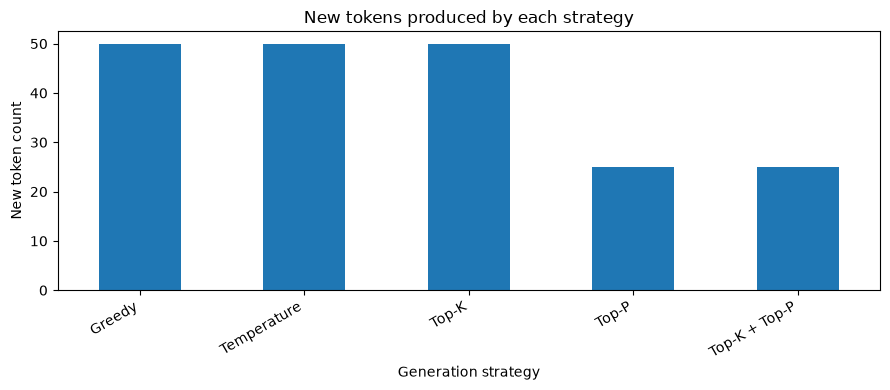

In [12]:
chart_df = comparison_df.set_index("Strategy")[["New tokens"]]
chart_df.plot(kind="bar", legend=False, figsize=(9, 4))
plt.title("New tokens produced by each strategy")
plt.ylabel("New token count")
plt.xlabel("Generation strategy")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 13. Definitions and interview questions

| Concept | Meaning |
|---|---|
| Autoregressive generation | Predict a token, append it to context, repeat |
| Greedy decoding | Select highest-scoring token each step |
| Sampling | Randomly select according to probabilities |
| Temperature | Controls probability-distribution sharpness |
| Top-K | Keeps a fixed number of candidate tokens |
| Top-P | Keeps a probability nucleus |
| Repetition penalty | Discourages repeated tokens |
| No-repeat n-gram | Blocks repeated n-token sequences |
| EOS | End-of-sequence token |
| KV cache | Reuses past attention keys and values |

**Interview questions**
1. Difference between next-token prediction and autoregressive generation?
2. Difference between `max_length` and `max_new_tokens`?
3. Greedy decoding vs sampling?
4. How do temperature, Top-K and Top-P affect generation?
5. What does repetition penalty do?
6. What does `no_repeat_ngram_size` do?
7. What is EOS?
8. What is KV cache and why does it improve inference efficiency?
9. Why use `model.eval()` and `torch.inference_mode()`?
10. Why does `generate()` need prompt token IDs?

**Module 5 checklist**
- [ ] Greedy generation
- [ ] Sampling and temperature
- [ ] Top-K and Top-P
- [ ] Repetition controls
- [ ] Compare generation strategies
- [ ] Implement and test `generate_text()`
- [ ] Understand EOS, max-new-token stopping and KV cache

**Scope:** This module uses a pretrained model's generation API. It does not train a language model, implement a Transformer from scratch, or implement KV cache internals.